# CQITE Validation Notebook
Validates CQITE against exact imaginary-time evolution.

In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
#from qitp.hamiltonians.pauli_hamiltonian import PauliString, PauliHamiltonian
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [5]:
h1 = 1
h2 = 1

Jz = 1

H = SparsePauliOp(
    ["XI", "IX", "ZZ"],
    coeffs=[1.0, 1.0, 1.0]
)

Hmat=H.to_matrix()


In [6]:
from qitp.hamiltonians.pauli_hamiltonian import (
    PauliString,
    PauliHamiltonian
)

Mz = SparsePauliOp(
    ["YY"],
    coeffs=[1.0]
)

Identity = SparsePauliOp(["II"],coeffs=[1.0])

In [7]:
def exact_ite_step(psi,dt):
    U=expm(-dt*Hmat)
    x=U@psi
    return x/np.linalg.norm(x)


In [143]:
from itertools import product

labels = []

for p in product(
    ["I","X","Y","Z"],
    repeat=2
):
    labels.append(
        "".join(p)
    )

In [145]:
#seeds = [SparsePauliOp(label) for label in labels]

seeds = [
    SparsePauliOp("ZI"),
    SparsePauliOp("IZ"),
    SparsePauliOp("XI"),
    SparsePauliOp("IX"),
    SparsePauliOp("YI"),
    SparsePauliOp("IY"),
]

In [149]:
#basis = PauliBasis(seeds)

basis = CommutatorBasis.from_seed(hamiltonian=H, seeds=seeds, depth=1)

In [151]:
basis.size

12

In [153]:
approx = UnitaryApproximation(basis)

backend=SimulatorBackend()

prop = QITEPropagation(
    H,
    approx,
    backend
)

prop.constraints = [
    Identity,
    Mz
]


In [155]:
psi0 = Statevector.from_label("10").data
state=Statevector(psi0)
psi_exact=psi0.copy()
dt=1e-1
nsteps=20

energies=[]
fidelities=[]
errors=[]
magnetizations=[]


In [157]:
from qiskit import QuantumCircuit

circuit = QuantumCircuit(H.num_qubits)

circuit.x(1)

In [159]:
for k in range(nsteps):
    psi_exact=exact_ite_step(psi_exact,dt)
    
    circuit, state = prop.step(
        circuit,
        state,
        dt
    )
    
    E=np.real(state.expectation_value(H))
    
    F=np.abs(np.vdot(psi_exact,state.data))**2
    
    err=np.linalg.norm(psi_exact-state.data)
    energies.append(E); fidelities.append(F); errors.append(err)
    Mz_value = np.real(
        state.expectation_value(
            Mz
        )
    )
    
    magnetizations.append(
        Mz_value
    )

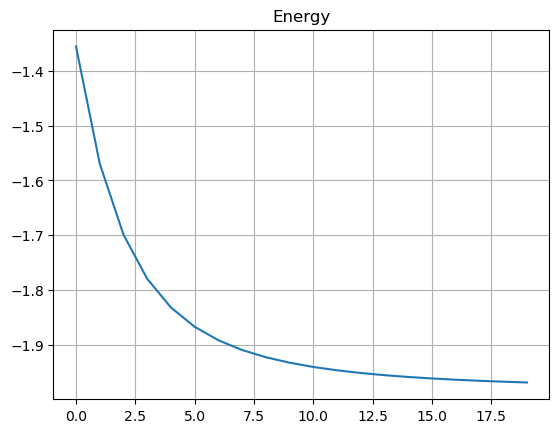

In [140]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()
#plt.plot(fidelities); plt.title('Fidelity'); plt.grid(); plt.show()

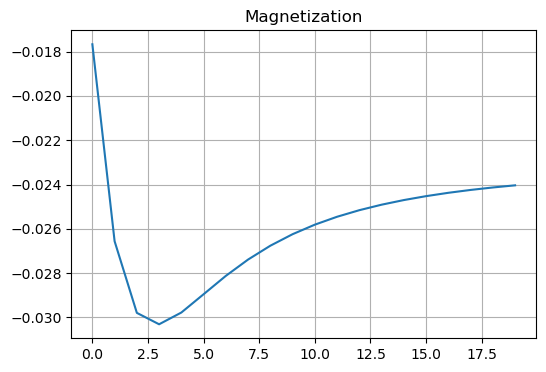

In [73]:
plt.figure(figsize=(6,4))

plt.plot(magnetizations)

plt.title("Magnetization")

plt.grid()

plt.show()

In [75]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

for e in evals:
    print(e)

Exact spectrum
-2.236067977499789
-1.0
0.9999999999999998
2.23606797749979


In [79]:
print(F)
print(fidelities[-1])

print(np.linalg.norm(psi_exact))
print(np.linalg.norm(state.data))

ov = np.vdot(psi_exact, state.data)
print(np.abs(ov))

0.9035385261373442
0.9035385261373442
1.0
0.9999999999999999
0.9505464355502808


In [81]:
import numpy as np
from scipy.optimize import root_scalar

Hm = H.to_matrix()
Mm = Mz.to_matrix()

target = 0.0


def mz_expectation(lam):

    Hc = Hm + lam * Mm

    E, V = np.linalg.eigh(Hc)

    psi = V[:, 0]

    return np.real(
        np.vdot(
            psi,
            Mm @ psi
        )
    )


sol = root_scalar(
    lambda lam:
        mz_expectation(lam) - target,
    bracket=[-100, 100]
)

lam = sol.root

Hc = Hm + lam * Mm

E, V = np.linalg.eigh(Hc)

psi_exact = V[:, 0]

E_exact = np.real(
    np.vdot(
        psi_exact,
        Hm @ psi_exact
    )
)

#print("lambda =", lam)
print("E_exact =", E_exact)

E_exact = -2.0000000000000138
